# Text classification - spam detector

We start by loading all necessary libraries and helper functions

In [ ]:
# Load libraries and helper functions
%run data_prep_tools.py
%run EDA_tools.py
%run modeling_tools.py


## Exploratory Data Analysis (EDA)

In the data preparation notebook we loaded a dataset containing ~6'000 labeled emails (spam and non-spam). We explored the email texts and decided on some procedures to clean the email text and extract both numerical features counting "spammish signatures" and text features. We also extracted embeddings of the original email text from a language model.

### Loading features  

All three feature spaces can be loaded using the `load_feature_space()`function.  

The parameter `features` specifies which of the above features you want to load. The options are:

The different feature sets can be loaded with the `load_feature_space()`-function. The feature sets are specified with the `features` parameter. The options are:
* "num": numerical features
* "text": (default) text features
* "num_text": numerical and text features combined
* "embedding": embedding features
  
The parameter `no_labels` controls whether we want to omit the labels. The options are:
- `True` to omit the labels
- `False` (default) to load the labels.



### Task 

Explore the different feature spaces.

Disclaimer: For easy of analysis we will analyze the full data set. In practice when building a supervised learning model like a spam filter you create a training set and a test set. You can explore the training set and used the insights to build your model. But you don't explore the test set as it is used to evaluate the performance of the model on unseen data. 

### Notebook overview

* Exploring the numeric features
* Exploring the text features
* Exploring the embeddings



In [3]:
labels = load_labels()

5832 labels loaded
Labels found: [1 0]


Let's start by exploring the distribution of the labels i.e. how many spam and non-spam emails we have.

<div class="alert alert-success">
<h3>Questions</h3>
    
__Q1.__ What do you observe for the frequency of spam and non-spam emails? 

__Q2.__ How could that impact the training of the spam detector?

</div>

Samples per class (%):
non-spam    70.3
spam        29.7
Name: spam_label, dtype: float64




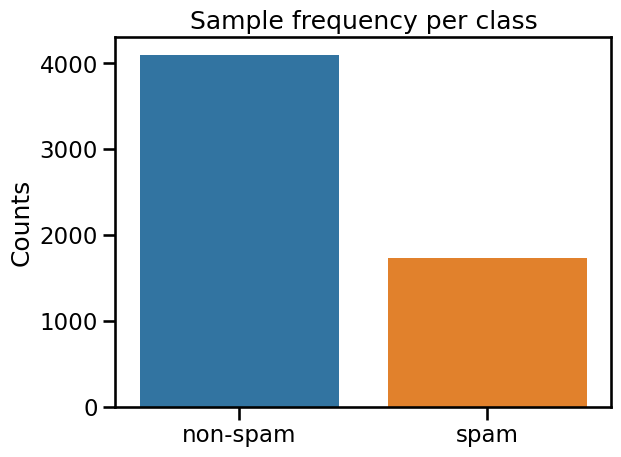

In [4]:
plot_class_frequency(labels)

#### Give your observations here:

1.    











## Exploring numeric features

#### Overview of numeric features
 The numeric features are:
- "email_counts"
- "html tag_counts"
- "url_counts"
- "Twitter username_counts"
- "hashtag_counts"
- "character_counts"
- "word_counts"
- "unique word_counts"
- "punctuation mark_counts"
- "uppercase word_counts"
- "lowercase word_counts"
- "digit_counts"
- "alphabetic char_counts"

Note some features have been log-scaled.

#### Load the numeric features:

In [68]:
num_features_df = load_feature_space(features="num")

Numeric features loaded
Data includes labels in the column 'spam_label'
The data set has 5832 rows, 14 columns


Let's check the distributions of the numeric features 
- once across the full corpus and
- once by `spam_label`   

and see whether there are signs of differences between spam and non-spam emails.

#### Full corpus:

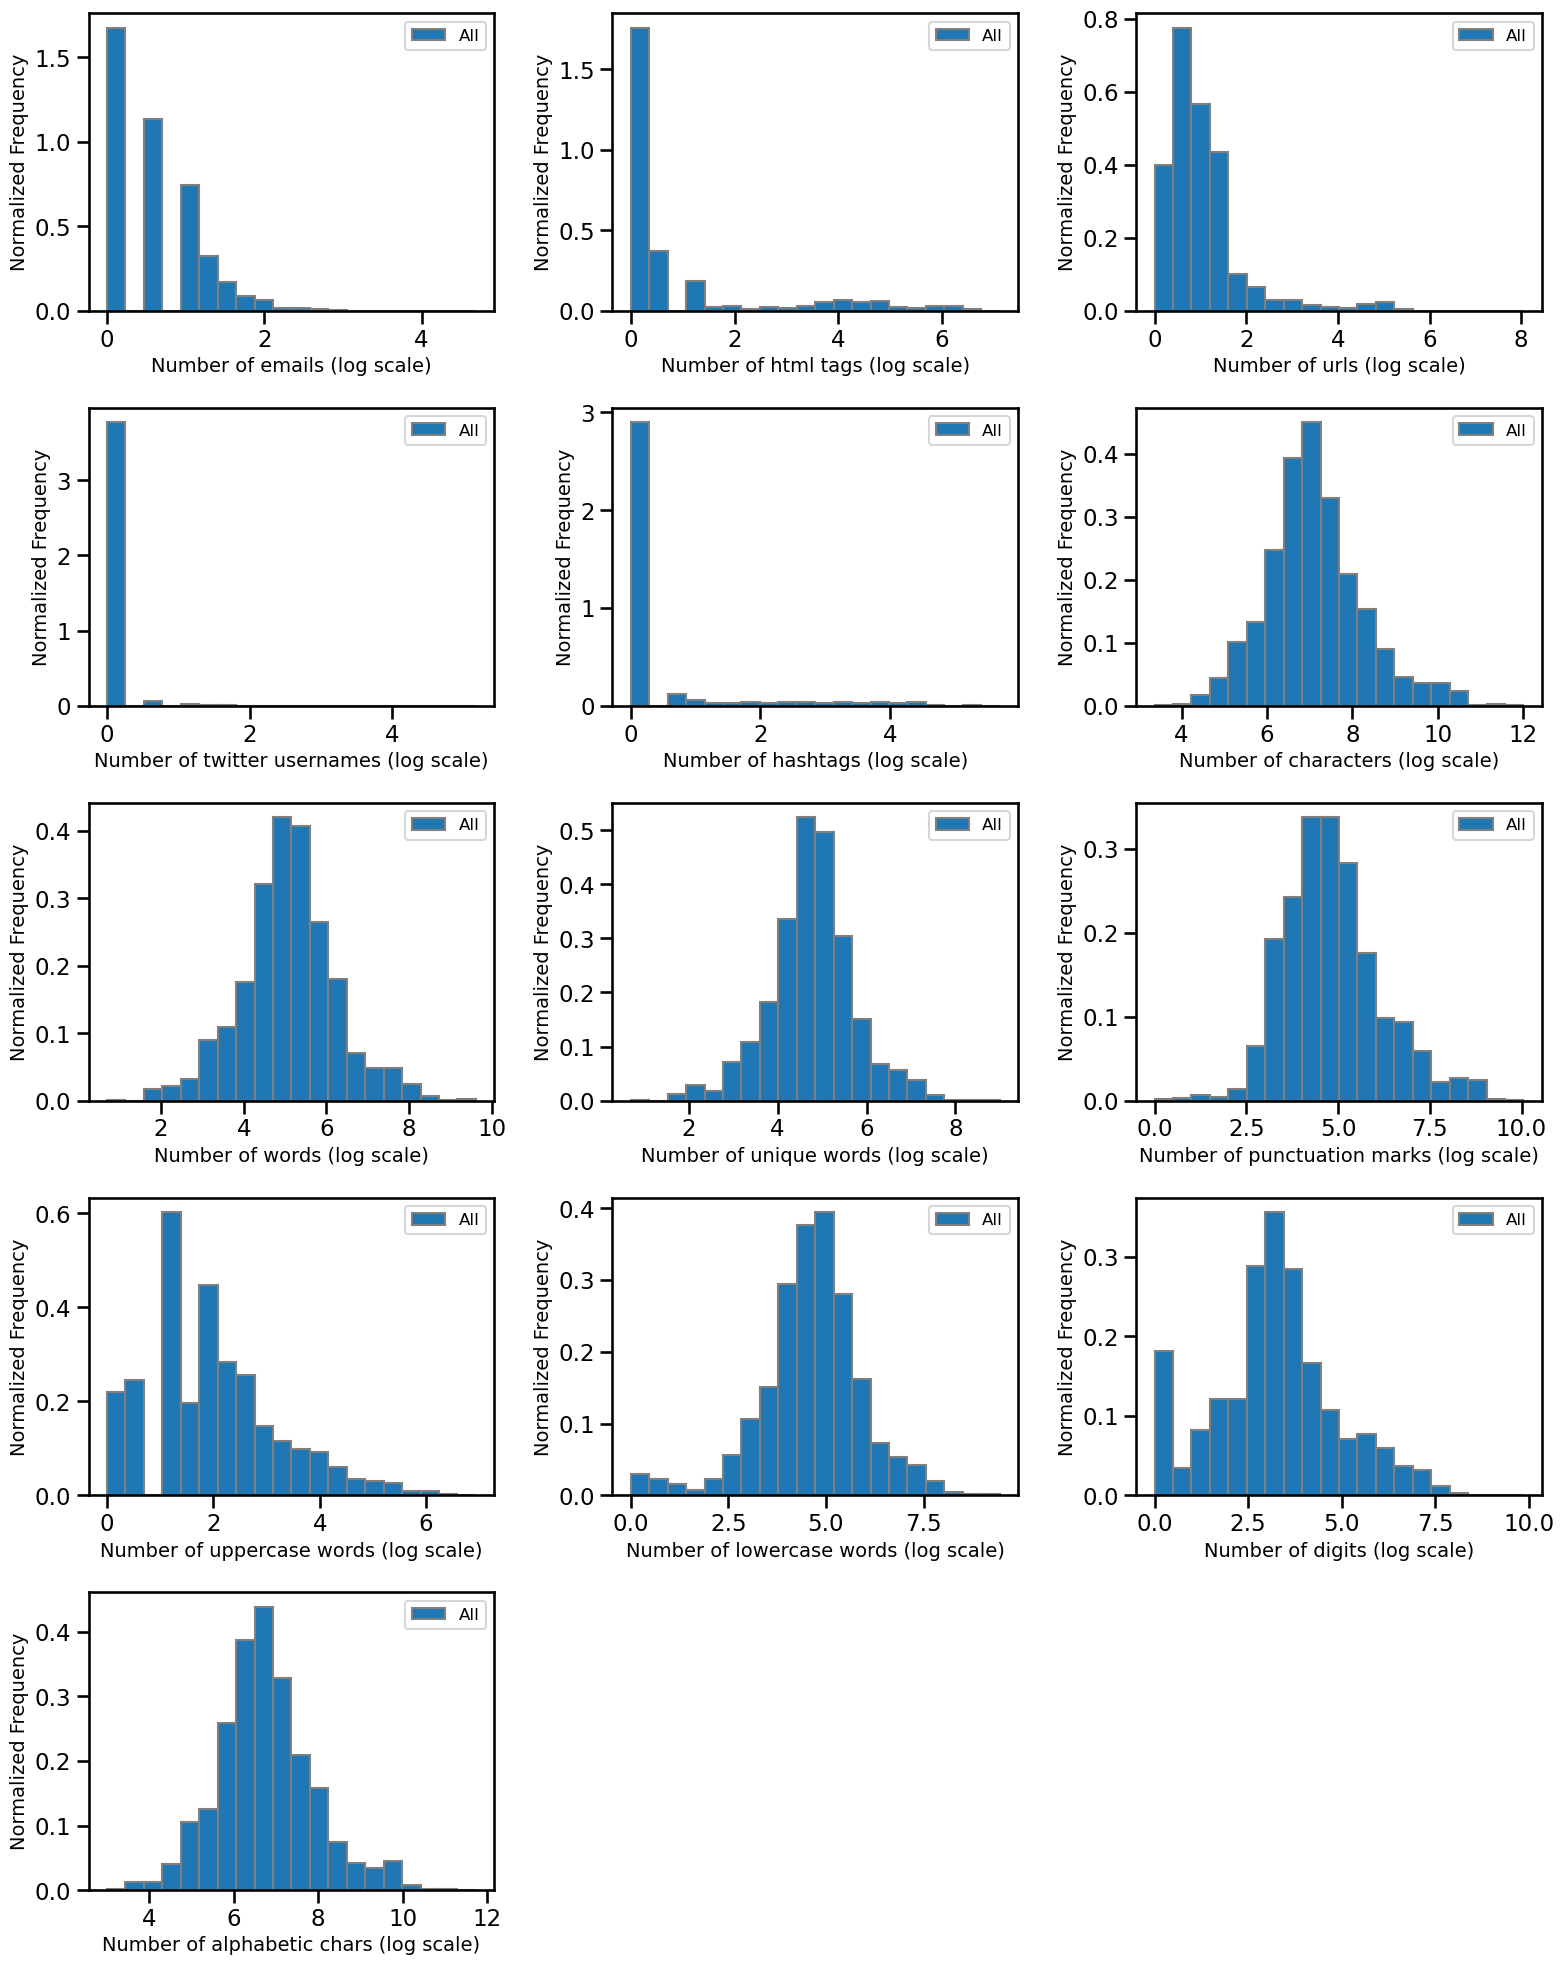

In [5]:
plot_numeric_features(num_features_df, with_labels=False)

#### Corpus split by `spam_label`:

<div class="alert alert-success">
<h3>Questions</h3>
    
__Q1.__ Do spam and non-spam emails differ on average across different numeric features?

* Do spams contain more HTML tags? 
* Does non-spam contain more URLs and E-mail adresses? 
* Are spams mails longer than non-spam? 
* ...
   
__Q2.__ Could these features be useful for the distinction of spam and non-spam emails?
</div>

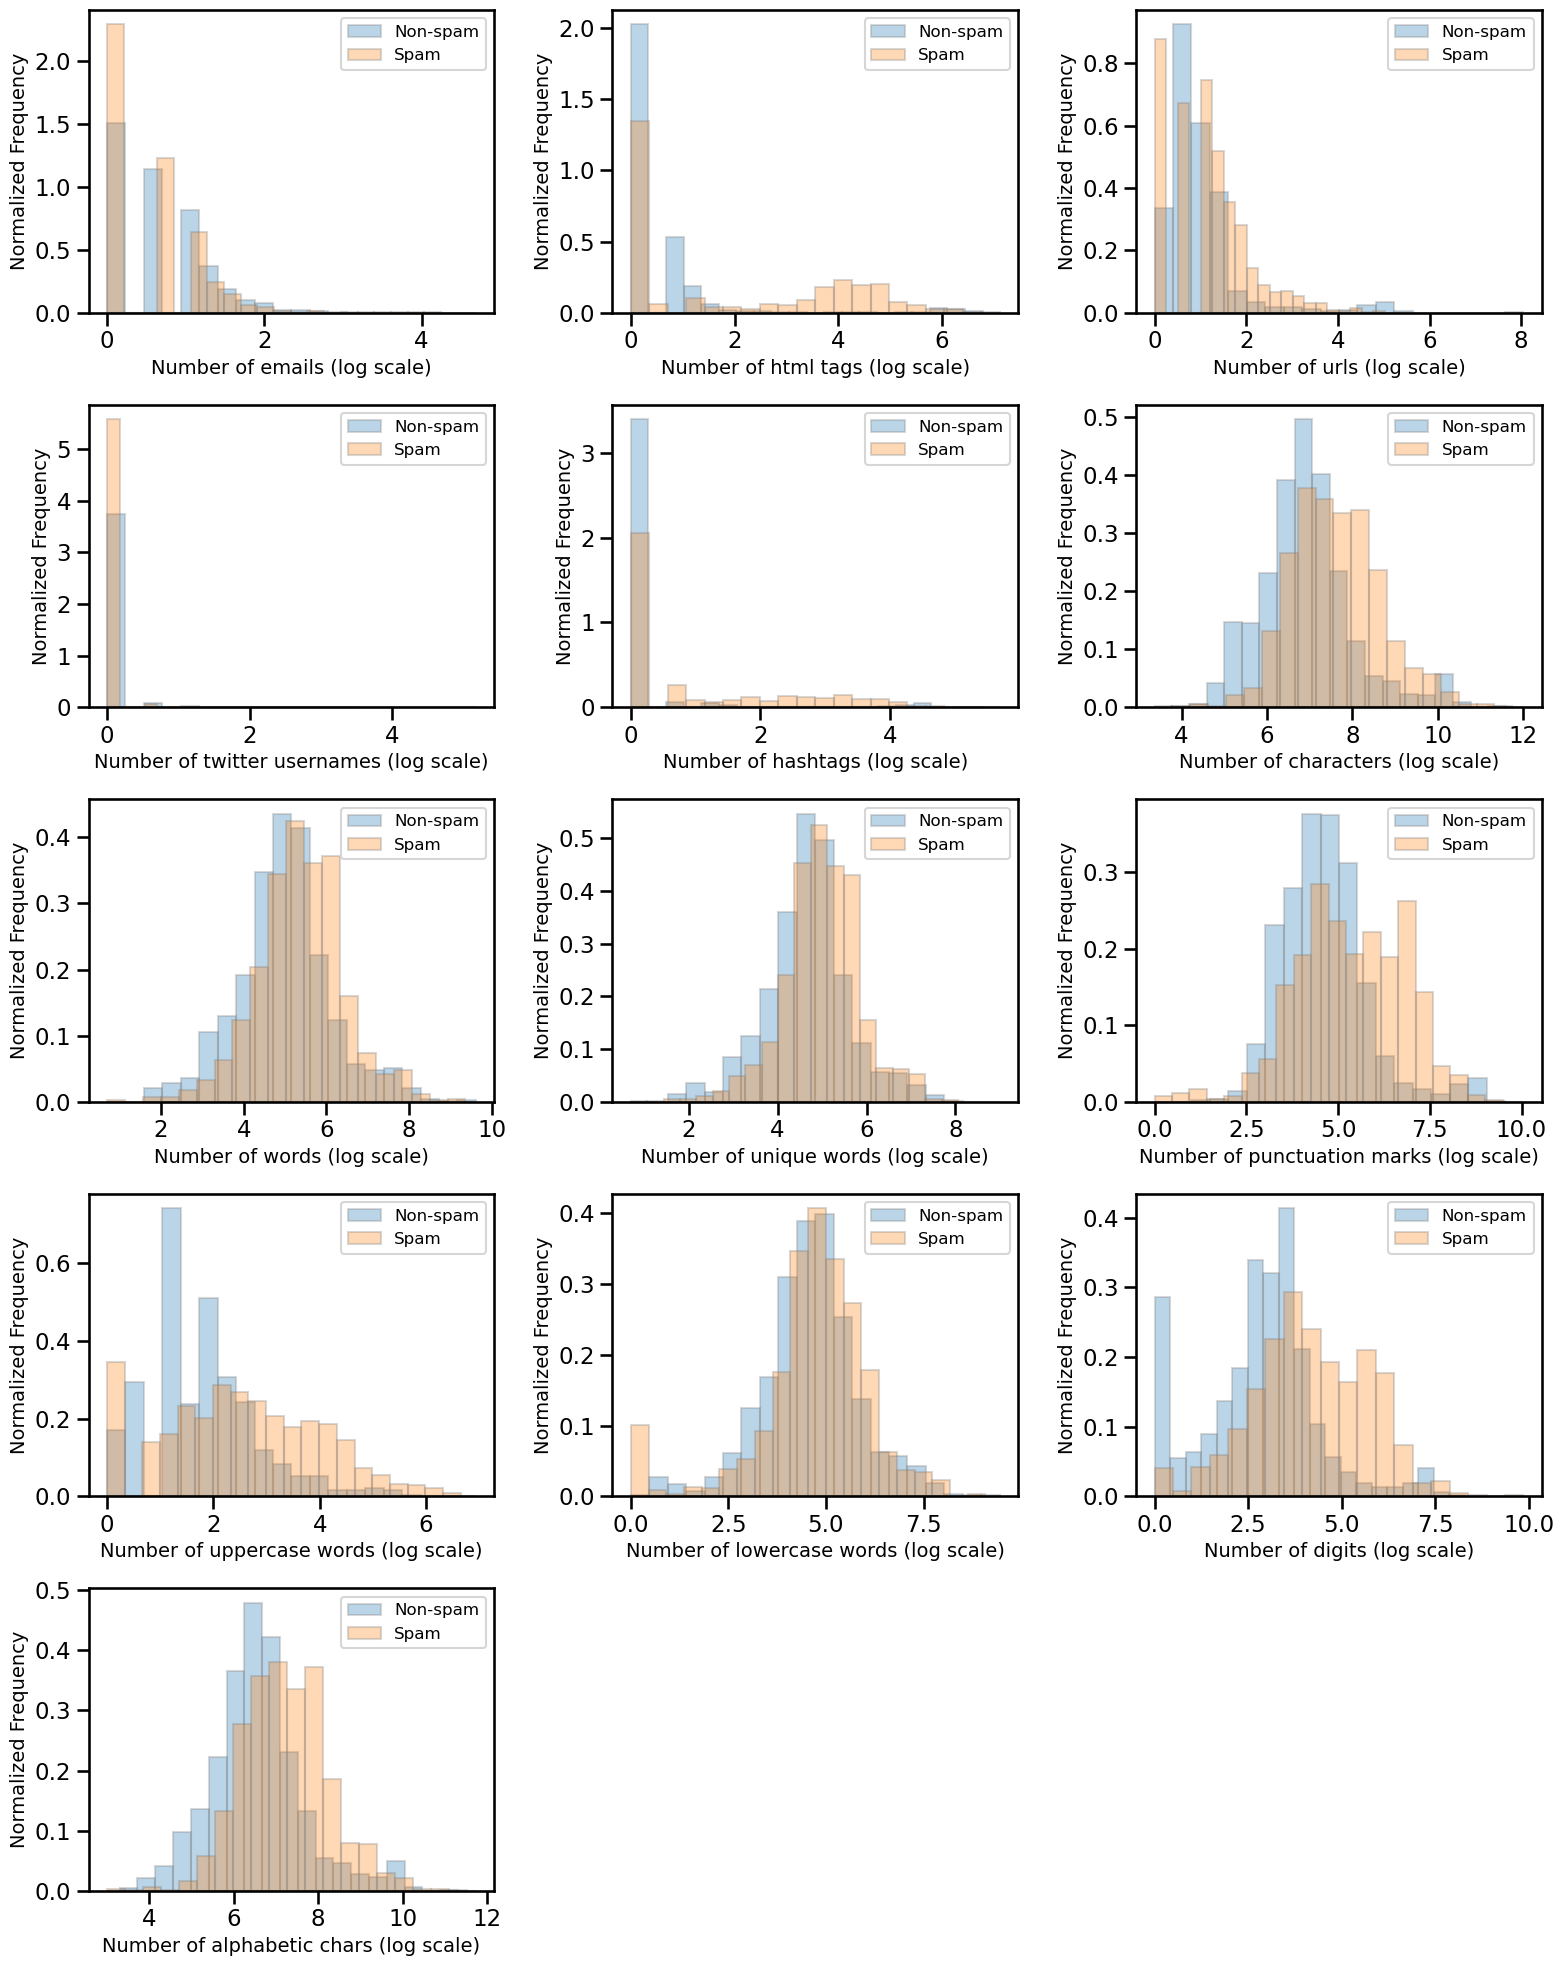

In [6]:
plot_numeric_features(num_features_df, with_labels=True)

#### Give your observations here:

**Q1**

-  

**Q2**

-  







## Exploring text features

It is easier to work with the cleaned text before we applied the vectorizers to generate a specific feature space.

#### Load the cleaned text::

In [9]:
df_source = load_source_data(verbose=False)
df_cleaned = clean_corpus(df_source, verbose=False)

Number of columns: 3
Columns names:
spam_label, text, text_cleaned



<div class="alert alert-success">


<h3>Questions</h3>

Let's explore the cleaned text for the most common words overall. You can change `N` to show more or less words.

__Q1.__ Which words do you think are more indicative of spam, and which are more typical of non-spam?

</div>

Top 30 words in all classes:
['list', 'email', 'free', 'just', 'time', 'mail', 'like', 'people', 'information', 'dont', 'make', 'click', 'mailing', 'business', 'message', 'linux', 'money', 'wrote', 'work', 'users', 'address', 'want', 'know', 'internet', 'send', 'software', 'need', 'home', 'spam', 'using']


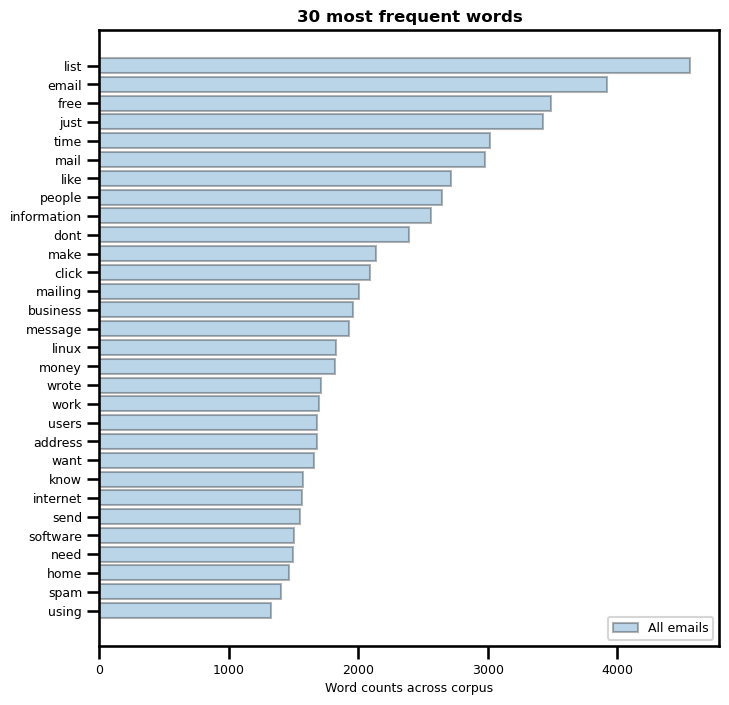

In [19]:
plot_most_common_words(df_cleaned, N=30, with_labels=False)

#### Give your observations here:

1.    











<div class="alert alert-success">


<h3>Questions</h3>

Now let's explore the most common words in each class. We are taking the top `N` words from each class and combining them into one set. We then plot the total counts of all these words for both classes. Thus you will get more than `N` words in the plot. The words are sorted by their frequency in the non-spam class (blue).

You can change `N` to show more or less words.

__Q1.__ Which words do you think are more indicative of spam, and which are more typical of non-spam?

__Q2.__ Are the total counts representative of the importance to each class?


</div>

Top 15 words in class 0:
['list', 'just', 'like', 'time', 'linux', 'dont', 'wrote', 'users', 'people', 'mail', 'message', 'email', 'mailing', 'information', 'spam']
Top 15 words in class 1:
['email', 'free', 'click', 'business', 'money', 'mail', 'list', 'information', 'time', 'people', 'address', 'just', 'order', 'send', 'receive']


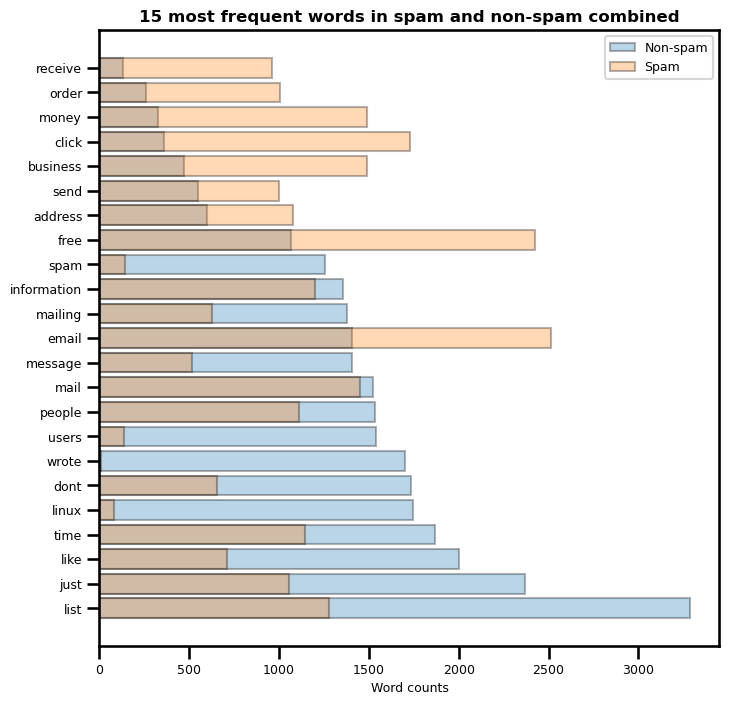

In [20]:
plot_most_common_tokens(df_cleaned, N=15)

#### Give your observations here:

1.    











<div class="alert alert-success">


<h3>Questions</h3>

Let's repeat the above counts but this time we __account for the different class sizes__. We will use the relative frequencies adjusted by adjusting our counts to 1000 documents per class.

__Q1.__ Which words do you think are more indicative of spam, and which are more typical of non-spam?

__Q2.__ What has changed in terms of words that appear to be good indicators for either class?

__Q3.__ Playing around a bit with `N`, do you think building a model based on text features can yield some good results?

</div>

Top 15 words in class 0:
['list', 'just', 'like', 'time', 'linux', 'dont', 'wrote', 'users', 'people', 'mail', 'message', 'email', 'mailing', 'information', 'spam']
Top 15 words in class 1:
['email', 'free', 'click', 'business', 'money', 'mail', 'list', 'information', 'time', 'people', 'address', 'just', 'order', 'send', 'receive']


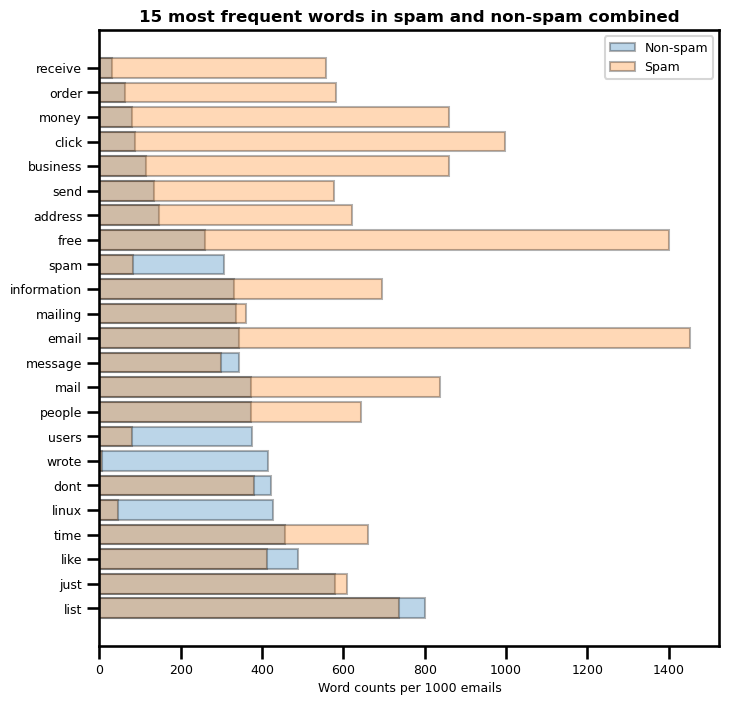

In [21]:
plot_most_common_tokens(df_cleaned, N=15, per_1000=True)

#### Give your observations here:

1.    











## Exploring the embedding space


In [24]:
embeddings_df = load_feature_space(features="embedding")

Email embeddings loaded
Data includes labels in the column 'spam_label'
The data set has 5832 rows, 769 columns


### PCA 

Very high dimensional space can cause problems for machine learning algorithms, because they may represent redundant information or noise. We thus want to explore whether we can reduce the dimensionality of our data set. In other words we want to compress the data to the most relevant information. This safes space, speeds up calculations and reduce noise.

A common method in machine learning is the **principal component analysis (PCA)** which iterativally indentifies the directions with within the data that have the highest variance. And then reduce the spaces by projecting the data only on the most relevant components.

**Note**: PCA is an _unsupervised machine learning method_, as it does not use any information about our target, the spam labels.

<div class="alert alert-success">


<h3>Questions</h3>

Below we run a PCA on the embedding space. We extract how many components explain a certain level of overall variance and visualize the results using a so called scree plot and a table.

We will also visualize the first two components in a scatter plot.

__Q1.__ How much variance is explained by the first two components?

__Q2.__ By how much could the feature space shrink if we wanted to retain 90% of variance?

__Q3.__ Looking at the scatterplot, what insights can you draw from the PCA results regarding class separation? 


</div>

Shape of data frame: (5832, 768)
Shape of labels: (5832,)
False    4101
True     1731
Name: spam_label, dtype: int64


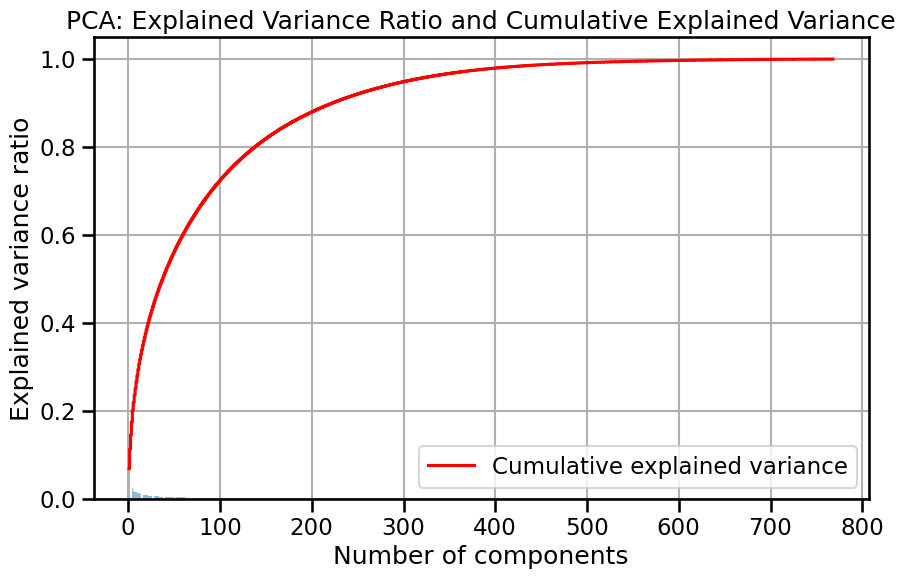

Number of components for 10% explained variance: 2
Number of components for 20% explained variance: 5
Number of components for 30% explained variance: 12
Number of components for 40% explained variance: 22
Number of components for 50% explained variance: 38
Number of components for 60% explained variance: 60
Number of components for 70% explained variance: 91
Number of components for 80% explained variance: 138
Number of components for 90% explained variance: 223
Number of components for 100% explained variance: 768


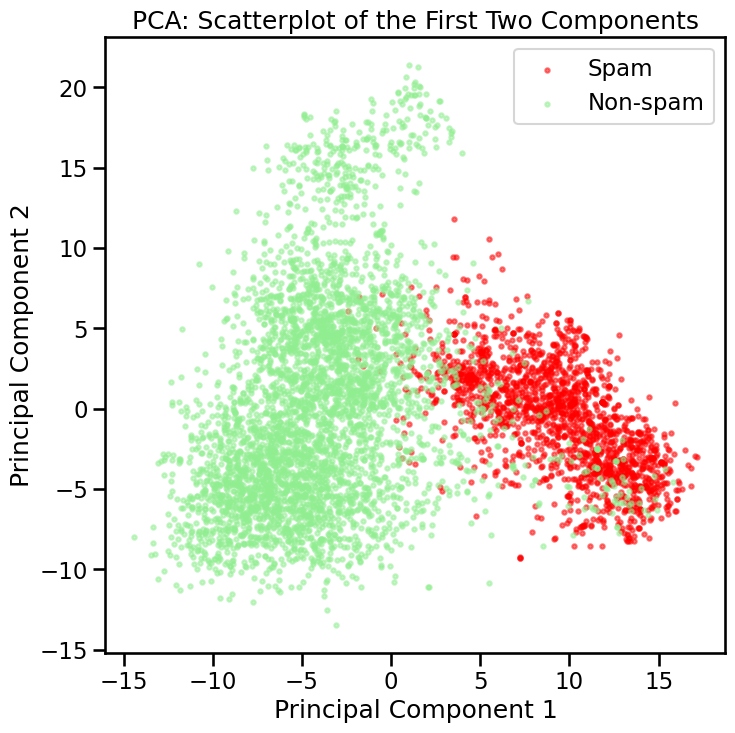

In [94]:
embeddings_pca_df = run_pca(embeddings_df, with_labels=True)

#### Give your observations here:

**Q1**




**Q2**
  



**Q3**

   









